In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("Results")
FIG_DIR = Path("Figures/Final")
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["LightGBM", "RF", "XGBoost"]
MODEL_ORDER = {m:i for i,m in enumerate(MODELS)}
LAMBDA_GRID = np.round(np.arange(0.0, 1.01, 0.1), 1)

# Known frozen realized-validation outputs
ORIGINAL_REALIZED_PATH = RESULTS_DIR / "additional_realised_validation_summary.csv"
ADDITIONAL_REALIZED_PATH = RESULTS_DIR / "additional_cohort_validation_summary.csv"

# IMPORTANT: set this explicitly if your frozen 33-run production summary uses another filename.
# The notebook will NOT fall back to legacy all_models_summary.csv.
PRODUCTION_CANDIDATES = [
    Path("Results/all_models_summary.csv")
]

print("Figure directory:", FIG_DIR.resolve())

Figure directory: E:\Github-assessment\Master-Project\Figures\Final


In [2]:
# ============================================================
# SAFETY HELPERS — reject Ridge / stale model labels
# ============================================================
def canonicalise_model(x):
    s = str(x).strip()
    aliases = {
        "LGB": "LightGBM", "LGBM": "LightGBM", "LightGBM": "LightGBM",
        "RF": "RF", "RandomForest": "RF", "Random Forest": "RF",
        "XGB": "XGBoost", "XGBoost": "XGBoost",
    }
    if s.lower() == "ridge":
        raise AssertionError("LEGACY RIDGE ARTIFACT DETECTED — aborting figure generation.")
    return aliases.get(s, s)

def normalise_columns(df):
    rename = {}
    aliases = {
        "lambda": "Lambda", "lam": "Lambda",
        "model": "Model",
        "objective": "Objective",
        "overtime": "Overtime",
        "makespan": "Makespan",
        "gap": "Gap", "mip_gap": "Gap", "milp_gap": "Gap",
        "solve_time": "Solve_Time", "milp_solve_time": "Solve_Time",
    }
    for c in df.columns:
        key = c.strip().lower()
        if key in aliases:
            rename[c] = aliases[key]
    return df.rename(columns=rename)

def audit_models(df, name):
    assert "Model" in df.columns, f"{name}: missing Model column"
    out = df.copy()
    out["Model"] = out["Model"].map(canonicalise_model)
    found = set(out["Model"].dropna().unique())
    unexpected = found - set(MODELS)
    assert not unexpected, f"{name}: unexpected model labels {unexpected}"
    assert set(MODELS).issubset(found), f"{name}: missing final models; found {found}"
    return out

def savefig(filename):
    path = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=600, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)

In [3]:
from pathlib import Path

print("=== Results directory ===")

results_dir = Path("Results")

if not results_dir.exists():
    print("Results directory does not exist.")
else:
    for p in sorted(results_dir.glob("*.csv")):
        print(
            f"{p.name:60s} "
            f"{p.stat().st_size / 1024:10.1f} KB"
        )

=== Results directory ===
ablation.csv                                                        9.7 KB
additional_cohort_validation_checkpoint.csv                         0.9 KB
additional_cohort_validation_room_results.csv                       2.0 KB
additional_cohort_validation_schedules.csv                         12.8 KB
additional_cohort_validation_summary.csv                            2.6 KB
additional_realised_validation_checkpoint.csv                       0.9 KB
additional_realised_validation_room_results.csv                     3.3 KB
additional_realised_validation_schedules.csv                       19.3 KB
additional_realised_validation_summary.csv                          3.6 KB
all_models_summary.csv                                             10.4 KB
all_models_summary_checkpoint.csv                                  10.4 KB
duration_cap_audit.csv                                              1.8 KB
duration_cap_audit_compact.csv                                      0.5 KB

In [4]:
import pandas as pd
from pathlib import Path

path = Path("Results/all_models_summary.csv")
df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nModels:")
if "Model" in df.columns:
    print(df["Model"].value_counts(dropna=False))

print("\nFirst rows:")
display(df.head())

print("\nLast rows:")
display(df.tail())

Shape: (33, 30)

Columns:
['Lambda', 'Time_Limit', 'Duration_Cap', 'N_Capped', 'Pct_Capped', 'Max_Uncapped_Duration', 'Max_Planning_Duration', 'Objective', 'Overtime', 'Idle', 'Makespan', 'Sched_Util', 'Cap_Util', 'Buffer_Ratio', 'Cap_Expansion', 'OnTime_Rate', 'Load_Gap', 'Solve_Time', 'Variables', 'Constraints', 'Nodes', 'Gap', 'Status', 'Reached_1pct_Gap', 'Hit_Time_Limit', 'Model', 'Solver_Failed', 'Failure_Type', 'Failure_Message', 'Run_Wall_Time']

Models:
Model
LightGBM    11
RF          11
XGBoost     11
Name: count, dtype: int64

First rows:


,Lambda,Time_Limit,Duration_Cap,N_Capped,Pct_Capped,Max_Uncapped_Duration,Max_Planning_Duration,Objective,Overtime,Idle,...,Nodes,Gap,Status,Reached_1pct_Gap,Hit_Time_Limit,Model,Solver_Failed,Failure_Type,Failure_Message,Run_Wall_Time
0,0.0,300,360.0,0,0.0,227.901180,227.901180,1280.221141,891.570972,0.0,...,3726489.0,0.597038,9,False,True,LightGBM,False,NaN,NaN,302.387456
1,0.1,300,360.0,0,0.0,237.388750,237.388750,1527.148923,1102.524203,0.0,...,3372181.0,0.581555,9,False,True,LightGBM,False,NaN,NaN,301.388758
2,0.2,300,360.0,0,0.0,249.829293,249.829293,1772.997101,1313.464804,0.0,...,3045043.0,0.567585,9,False,True,LightGBM,False,NaN,NaN,301.253394
3,0.3,300,360.0,0,0.0,270.869344,270.869344,2019.771679,1524.430723,0.0,...,3043441.0,0.570917,9,False,True,LightGBM,False,NaN,NaN,301.298751
4,0.4,300,360.0,0,0.0,295.316983,295.316983,2264.806814,1735.384186,0.0,...,2814236.0,0.479702,9,False,True,LightGBM,False,NaN,NaN,301.368440



Last rows:


,Lambda,Time_Limit,Duration_Cap,N_Capped,Pct_Capped,Max_Uncapped_Duration,Max_Planning_Duration,Objective,Overtime,Idle,...,Nodes,Gap,Status,Reached_1pct_Gap,Hit_Time_Limit,Model,Solver_Failed,Failure_Type,Failure_Message,Run_Wall_Time
28,0.6,300,360.0,0,0.000000,297.503592,297.503592,2758.704091,2158.848481,0.0,...,3535536.0,0.468481,9,False,True,XGBoost,False,NaN,NaN,301.490252
29,0.7,300,360.0,0,0.000000,318.836739,318.836739,3021.533282,2382.069180,0.0,...,3395185.0,0.465934,9,False,True,XGBoost,False,NaN,NaN,301.372990
30,0.8,300,360.0,0,0.000000,340.169886,340.169886,3283.238825,2605.290394,0.0,...,3287628.0,0.455458,9,False,True,XGBoost,False,NaN,NaN,301.384169
31,0.9,300,360.0,1,8.333333,361.503033,360.000000,3543.327611,2827.008303,0.0,...,3216859.0,0.455125,9,False,True,XGBoost,False,NaN,NaN,301.321183
32,1.0,300,360.0,9,75.000000,382.836180,360.000000,3749.260302,3007.937402,0.0,...,2861744.0,0.452658,9,False,True,XGBoost,False,NaN,NaN,301.121609


In [5]:
for model in ["LightGBM", "RF", "XGBoost"]:
    sub = df[df["Model"] == model]
    print(
        model,
        sorted(sub["Lambda"].astype(float).round(1).tolist())
    )

LightGBM [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
RF [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
XGBoost [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


In [6]:
check = df[
    ["Model", "Lambda", "Objective"]
].copy()

targets = {
    ("LightGBM", 0.0): 1280.221141,
    ("LightGBM", 0.5): 2511.684004,
    ("LightGBM", 1.0): 3589.642349,

    ("RF", 0.0): 1134.918644,
    ("RF", 0.5): 1241.366899,
    ("RF", 1.0): 1350.060817,

    ("XGBoost", 0.0): 1213.970611,
    ("XGBoost", 0.5): 2498.640313,
    ("XGBoost", 1.0): 3749.260302,
}

for (model, lam), expected in targets.items():

    row = check[
        (check["Model"] == model)
        &
        (check["Lambda"].astype(float).round(6) == lam)
    ]

    assert len(row) == 1, f"Missing/duplicate: {model}, λ={lam}"

    actual = float(row.iloc[0]["Objective"])

    assert abs(actual - expected) < 1e-4, (
        f"{model}, λ={lam}: "
        f"expected {expected}, found {actual}"
    )

    print(
        f"PASS | {model:10s} | "
        f"λ={lam:.1f} | Objective={actual:.6f}"
    )

print("\nFINAL 33-RUN FINGERPRINT AUDIT: PASS")

PASS | LightGBM   | λ=0.0 | Objective=1280.221141
PASS | LightGBM   | λ=0.5 | Objective=2511.684004
PASS | LightGBM   | λ=1.0 | Objective=3589.642349
PASS | RF         | λ=0.0 | Objective=1134.918644
PASS | RF         | λ=0.5 | Objective=1241.366899
PASS | RF         | λ=1.0 | Objective=1350.060817
PASS | XGBoost    | λ=0.0 | Objective=1213.970611
PASS | XGBoost    | λ=0.5 | Objective=2498.640313
PASS | XGBoost    | λ=1.0 | Objective=3749.260302

FINAL 33-RUN FINGERPRINT AUDIT: PASS


In [7]:
# ============================================================
# LOAD + AUDIT FROZEN 33-RUN PRODUCTION SUMMARY
# ============================================================
existing = [p for p in PRODUCTION_CANDIDATES if p.exists()]
if not existing:
    raise FileNotFoundError(
        "Frozen 33-run production summary not found. Set PRODUCTION_CANDIDATES to the exact final CSV filename. "
        "Do NOT use Results/all_models_summary.csv or any Ridge-labelled file."
    )

PRODUCTION_PATH = existing[0]
prod = normalise_columns(pd.read_csv(PRODUCTION_PATH))
prod = audit_models(prod, "production summary")

required = {"Model", "Lambda", "Objective", "Overtime", "Makespan", "Gap"}
missing = required - set(prod.columns)
assert not missing, f"Production summary missing columns: {missing}"

prod["Lambda"] = prod["Lambda"].astype(float).round(1)
assert len(prod) == 33, f"Expected 33 production runs, found {len(prod)}"
assert not prod.duplicated(["Model", "Lambda"]).any(), "Duplicate Model/Lambda rows detected"
for m in MODELS:
    got = np.sort(prod.loc[prod.Model == m, "Lambda"].unique())
    assert np.allclose(got, LAMBDA_GRID), f"{m}: incomplete lambda grid {got}"

print("PRODUCTION SUMMARY AUDIT: PASS")
print("Source:", PRODUCTION_PATH)
print("Rows:", len(prod))
display(prod.groupby("Model").agg(Runs=("Lambda","size"), Mean_Gap=("Gap","mean"), Median_Gap=("Gap","median")))

PRODUCTION SUMMARY AUDIT: PASS
Source: Results\all_models_summary.csv
Rows: 33


,Runs,Mean_Gap,Median_Gap
Model,,,
LightGBM,11,0.511325,0.482754
RF,11,0.587596,0.580903
XGBoost,11,0.505514,0.485555


In [8]:
# ============================================================
# FROZEN PREDICTIVE PERFORMANCE
# Values are the final leakage-corrected held-out test results.
# ============================================================
predictive = pd.DataFrame({
    "Model": ["LightGBM", "RF", "XGBoost"],
    "P50_MAE": [74.76, 93.90, 85.13],
    "P10_Lower_Coverage": [90.19, 60.58, 90.27],
    "P90_Upper_Coverage": [89.74, 59.14, 89.83],
    "P10_P90_Interval_Coverage": [79.93, 19.72, 80.09],
    "N_Test": [17083, 17083, 17083],
})
assert predictive["N_Test"].eq(17083).all()
display(predictive)

,Model,P50_MAE,P10_Lower_Coverage,P90_Upper_Coverage,P10_P90_Interval_Coverage,N_Test
0,LightGBM,74.76,90.19,89.74,79.93,17083
1,RF,93.90,60.58,59.14,19.72,17083
2,XGBoost,85.13,90.27,89.83,80.09,17083


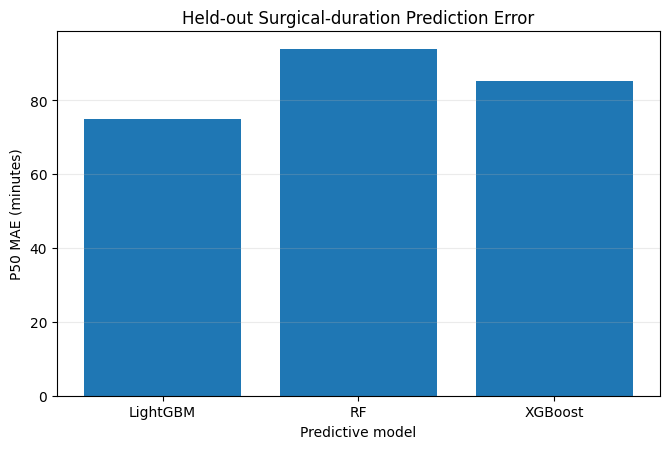

Saved: Figures\Final\01_predictive_p50_mae.png


In [9]:
# Figure 1 — Predictive P50 MAE
plt.figure(figsize=(6.8, 4.6))
plt.bar(predictive["Model"], predictive["P50_MAE"])
plt.ylabel("P50 MAE (minutes)")
plt.xlabel("Predictive model")
plt.title("Held-out Surgical-duration Prediction Error")
plt.grid(axis="y", alpha=0.25)
savefig("01_predictive_p50_mae.png")

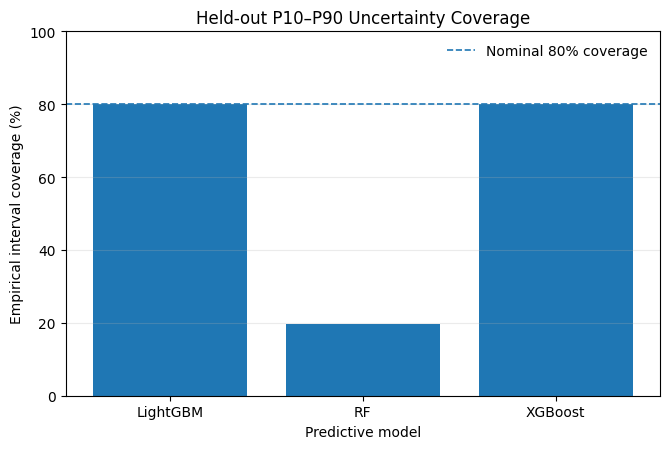

Saved: Figures\Final\02_predictive_interval_coverage.png


In [10]:
# Figure 2 — Empirical P10–P90 interval coverage
plt.figure(figsize=(6.8, 4.6))
plt.bar(predictive["Model"], predictive["P10_P90_Interval_Coverage"])
plt.axhline(80, linestyle="--", linewidth=1.2, label="Nominal 80% coverage")
plt.ylabel("Empirical interval coverage (%)")
plt.xlabel("Predictive model")
plt.title("Held-out P10–P90 Uncertainty Coverage")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.legend(frameon=False)
savefig("02_predictive_interval_coverage.png")

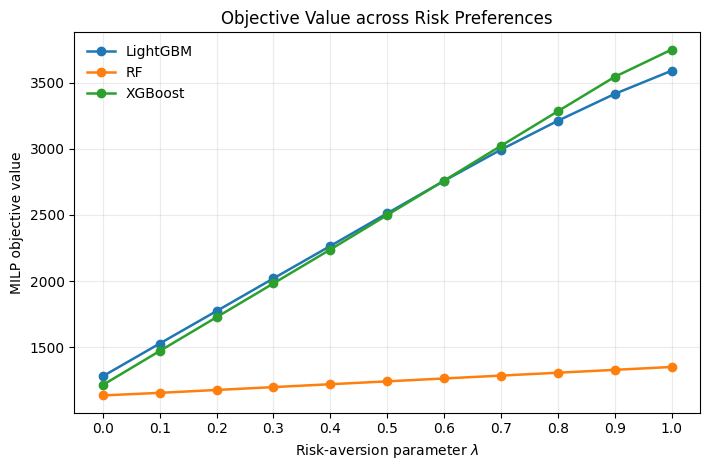

Saved: Figures\Final\03_objective_vs_lambda.png


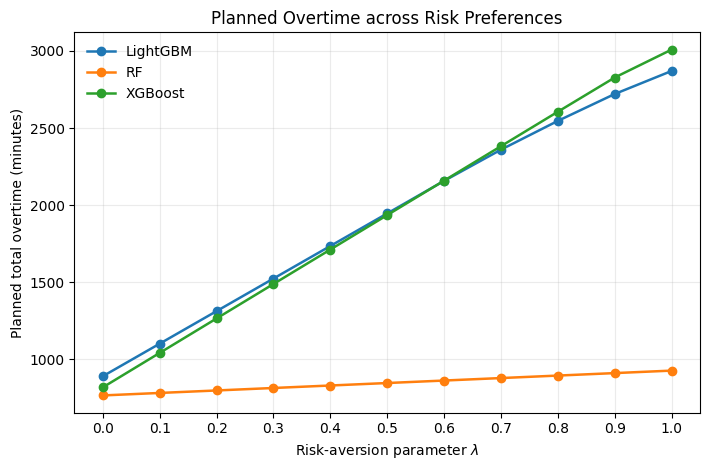

Saved: Figures\Final\04_planned_overtime_vs_lambda.png


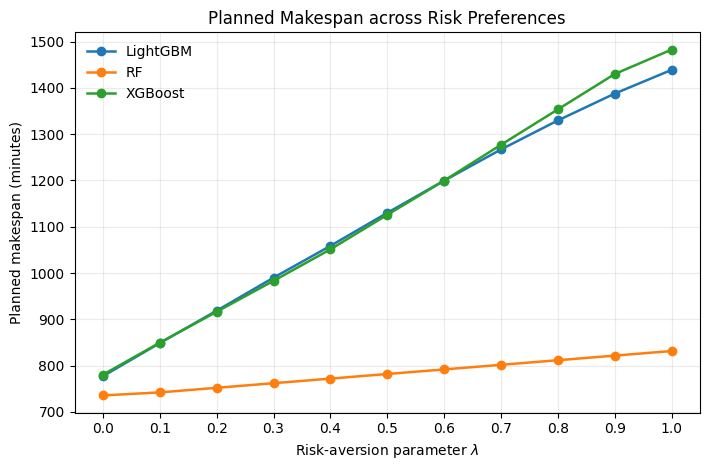

Saved: Figures\Final\05_planned_makespan_vs_lambda.png


In [11]:
# ============================================================
# COMMON PRODUCTION CURVE FUNCTION
# ============================================================
def plot_production_metric(metric, ylabel, title, filename):
    plt.figure(figsize=(7.2, 4.8))
    for model in MODELS:
        d = prod[prod.Model == model].sort_values("Lambda")
        plt.plot(d["Lambda"], d[metric], marker="o", linewidth=1.8, label=model)
    plt.xlabel(r"Risk-aversion parameter $\lambda$")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(LAMBDA_GRID)
    plt.grid(alpha=0.25)
    plt.legend(frameon=False)
    savefig(filename)

plot_production_metric("Objective", "MILP objective value", "Objective Value across Risk Preferences", "03_objective_vs_lambda.png")
plot_production_metric("Overtime", "Planned total overtime (minutes)", "Planned Overtime across Risk Preferences", "04_planned_overtime_vs_lambda.png")
plot_production_metric("Makespan", "Planned makespan (minutes)", "Planned Makespan across Risk Preferences", "05_planned_makespan_vs_lambda.png")

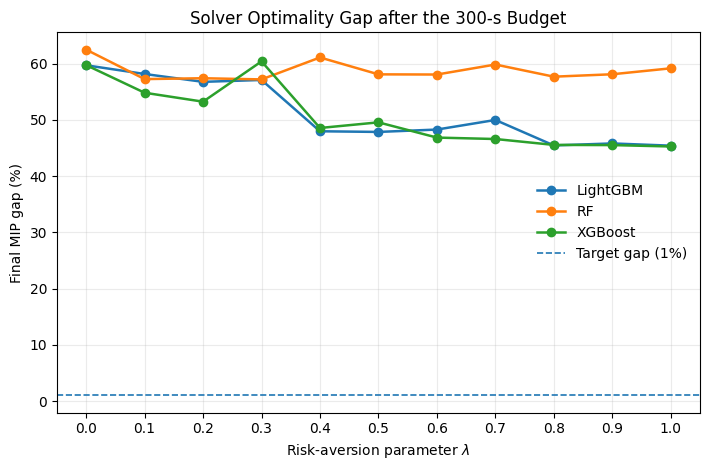

Saved: Figures\Final\06_mip_gap_vs_lambda.png


In [12]:
# Figure 6 — Final MIP gap vs lambda
# Convert to percent if stored as a fraction.
gap_plot = prod.copy()
if gap_plot["Gap"].max() <= 1.5:
    gap_plot["Gap_Percent"] = 100 * gap_plot["Gap"]
else:
    gap_plot["Gap_Percent"] = gap_plot["Gap"]

plt.figure(figsize=(7.2, 4.8))
for model in MODELS:
    d = gap_plot[gap_plot.Model == model].sort_values("Lambda")
    plt.plot(d["Lambda"], d["Gap_Percent"], marker="o", linewidth=1.8, label=model)
plt.axhline(1, linestyle="--", linewidth=1.2, label="Target gap (1%)")
plt.xlabel(r"Risk-aversion parameter $\lambda$")
plt.ylabel("Final MIP gap (%)")
plt.title("Solver Optimality Gap after the 300-s Budget")
plt.xticks(LAMBDA_GRID)
plt.grid(alpha=0.25)
plt.legend(frameon=False)
savefig("06_mip_gap_vs_lambda.png")

In [14]:
# ============================================================
# LOAD + AUDIT ORIGINAL-COHORT REALIZED VALIDATION (9 runs)
# ============================================================
assert ORIGINAL_REALIZED_PATH.exists(), f"Missing {ORIGINAL_REALIZED_PATH}"
orig = pd.read_csv(ORIGINAL_REALIZED_PATH)
orig = audit_models(orig, "original realized validation")
assert len(orig.drop_duplicates(["Model","Lambda"])) == 9
assert set(np.round(orig["Lambda"].astype(float), 1)) == {0.0, 0.5, 1.0}
assert orig["Replay_Turnover_Violations"].eq(0).all()
assert orig["MILP_Hit_Time_Limit"].astype(bool).all()
print("ORIGINAL REALIZED VALIDATION AUDIT: PASS")
display(orig[["Model","Lambda","Realised_Makespan","Realised_Overtime","Total_Start_Delay","Delayed_Cases","MILP_N_Capped","MILP_Gap"]].sort_values(["Lambda","Model"]))

ORIGINAL REALIZED VALIDATION AUDIT: PASS


,Model,Lambda,Realised_Makespan,Realised_Overtime,Total_Start_Delay,Delayed_Cases,MILP_N_Capped,MILP_Gap
0,LightGBM,0.0,1125.000000,1250.052660,718.514094,4,0,0.600397
2,RF,0.0,1125.000000,1352.722176,733.541207,4,0,0.625020
4,XGBoost,0.0,1115.504710,1304.886977,406.278658,4,0,0.598912
6,LightGBM,0.5,1141.727962,1616.559004,250.413029,4,0,0.478095
7,RF,0.5,1067.158628,1182.430073,557.408732,6,0,0.606748
8,XGBoost,0.5,1115.451530,1817.923189,222.566486,2,0,0.549075
1,LightGBM,1.0,1520.976265,2409.833777,81.223119,1,4,0.453939
3,RF,1.0,1071.399382,1392.072046,318.609424,4,0,0.627410
5,XGBoost,1.0,1490.645801,2746.937402,61.354424,1,9,0.448362


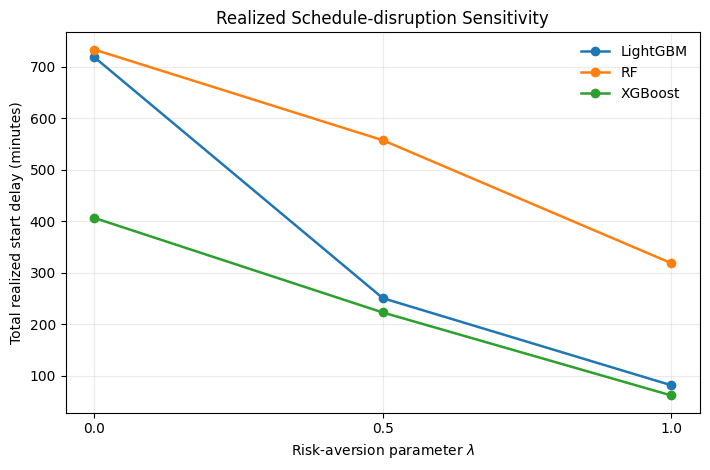

Saved: Figures\Final\07_realized_start_delay_vs_lambda.png


In [15]:
# Figure 7 — Realized start-delay sensitivity
plt.figure(figsize=(7.2, 4.8))
for model in MODELS:
    d = orig[orig.Model == model].sort_values("Lambda")
    plt.plot(d["Lambda"], d["Total_Start_Delay"], marker="o", linewidth=1.8, label=model)
plt.xlabel(r"Risk-aversion parameter $\lambda$")
plt.ylabel("Total realized start delay (minutes)")
plt.title("Realized Schedule-disruption Sensitivity")
plt.xticks([0.0, 0.5, 1.0])
plt.grid(alpha=0.25)
plt.legend(frameon=False)
savefig("07_realized_start_delay_vs_lambda.png")

In [17]:
# ============================================================
# LOAD + AUDIT ADDITIONAL-COHORT VALIDATION (6 runs)
# ============================================================
assert ADDITIONAL_REALIZED_PATH.exists(), f"Missing {ADDITIONAL_REALIZED_PATH}"
add = pd.read_csv(ADDITIONAL_REALIZED_PATH)
add = audit_models(add, "additional cohort validation")
assert len(add.drop_duplicates(["Cohort","Model","Lambda"])) == 6
assert np.allclose(add["Lambda"].astype(float), 0.5)
assert add["Replay_Turnover_Violations"].eq(0).all()
assert add["MILP_Hit_Time_Limit"].astype(bool).all()

# Original cohort at lambda=.5 + two fixed-seed additional cohorts
orig_mid = orig[np.isclose(orig["Lambda"].astype(float), 0.5)].copy()
orig_mid["Cohort"] = "Original_Fixed_Cohort"
robust = pd.concat([orig_mid, add], ignore_index=True)
assert len(robust) == 9
assert robust.groupby("Cohort")["Model"].nunique().eq(3).all()
print("CROSS-COHORT REALIZED VALIDATION AUDIT: PASS")
display(robust[["Cohort","Model","Actual_Capacity_Load_Ratio","Realised_Makespan","Realised_Overtime","Total_Start_Delay","Delayed_Cases","MILP_Gap"]].sort_values(["Cohort","Model"]))

CROSS-COHORT REALIZED VALIDATION AUDIT: PASS


,Cohort,Model,Actual_Capacity_Load_Ratio,Realised_Makespan,Realised_Overtime,Total_Start_Delay,Delayed_Cases,MILP_Gap
3,Additional_Cohort_A,LightGBM,1.293056,1109.174445,1484.520420,17.133341,1,0.468783
4,Additional_Cohort_A,RF,1.293056,987.550860,1116.665074,76.069290,2,0.603366
5,Additional_Cohort_A,XGBoost,1.293056,963.909375,1353.045357,283.451365,2,0.459627
6,Additional_Cohort_B,LightGBM,1.166667,901.703115,1024.713910,22.192126,2,0.384571
7,Additional_Cohort_B,RF,1.166667,863.543589,944.623865,347.637522,2,0.631657
8,Additional_Cohort_B,XGBoost,1.166667,969.214075,1321.942439,49.937275,1,0.441334
0,Original_Fixed_Cohort,LightGBM,1.522222,1141.727962,1616.559004,250.413029,4,0.478095
1,Original_Fixed_Cohort,RF,1.522222,1067.158628,1182.430073,557.408732,6,0.606748
2,Original_Fixed_Cohort,XGBoost,1.522222,1115.451530,1817.923189,222.566486,2,0.549075


FIGURE 8 DATA AUDIT: PASS


,Cohort,Model,Lambda,Realised_Overtime,Total_Start_Delay
0,Additional_Cohort_A,LightGBM,0.5,1484.520420,17.133341
1,Additional_Cohort_A,RF,0.5,1116.665074,76.069290
2,Additional_Cohort_A,XGBoost,0.5,1353.045357,283.451365
3,Additional_Cohort_B,LightGBM,0.5,1024.713910,22.192126
4,Additional_Cohort_B,RF,0.5,944.623865,347.637522
5,Additional_Cohort_B,XGBoost,0.5,1321.942439,49.937275
6,Original_Fixed_Cohort,LightGBM,0.5,1616.559004,250.413029
7,Original_Fixed_Cohort,RF,0.5,1182.430073,557.408732
8,Original_Fixed_Cohort,XGBoost,0.5,1817.923189,222.566486


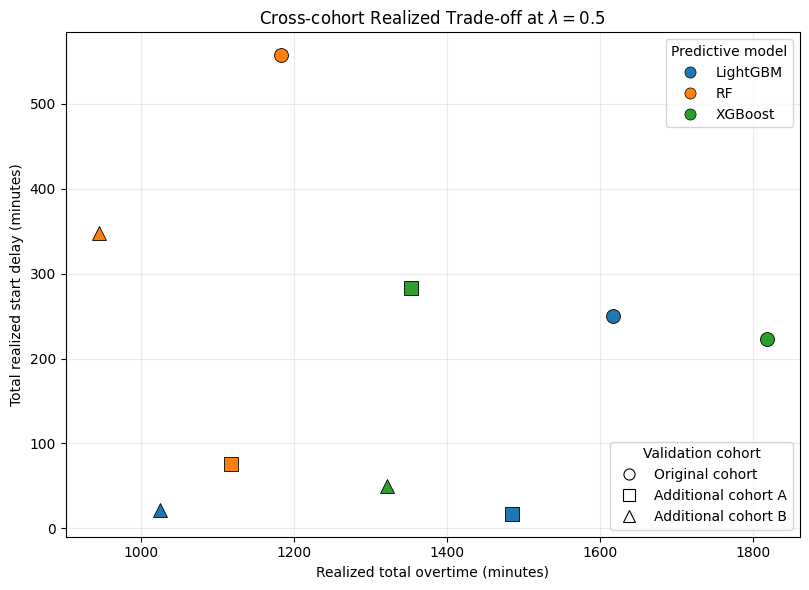


Figure 8 regenerated successfully.
PNG: Figures\final\08_cross_cohort_realized_tradeoff.png
PDF: Figures\final\08_cross_cohort_realized_tradeoff.pdf


In [24]:
# ============================================================
# FIGURE 8
# Cross-cohort realized overtime–delay trade-off at lambda=0.5
#
# Colour = predictive model
# Marker = validation cohort
#
# This cell reads the frozen realized-validation outputs
# directly and does not depend on an earlier notebook variable.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

RESULTS_DIR = Path("Results")

ORIGINAL_VALIDATION_PATH = (
    RESULTS_DIR /
    "additional_realised_validation_summary.csv"
)

ADDITIONAL_COHORT_PATH = (
    RESULTS_DIR /
    "additional_cohort_validation_summary.csv"
)


assert ORIGINAL_VALIDATION_PATH.exists(), (
    f"Missing file: {ORIGINAL_VALIDATION_PATH}"
)

assert ADDITIONAL_COHORT_PATH.exists(), (
    f"Missing file: {ADDITIONAL_COHORT_PATH}"
)


# ------------------------------------------------------------
# Load frozen realized-validation results
# ------------------------------------------------------------

original_df = pd.read_csv(
    ORIGINAL_VALIDATION_PATH
)

additional_df = pd.read_csv(
    ADDITIONAL_COHORT_PATH
)


# ------------------------------------------------------------
# Original cohort:
# retain lambda = 0.5 only
# ------------------------------------------------------------

original_lambda05 = original_df[
    np.isclose(
        original_df["Lambda"].astype(float),
        0.5
    )
].copy()


assert len(original_lambda05) == 3, (
    "Expected exactly 3 original-cohort "
    "model results at lambda=0.5."
)


# Standardise cohort name
original_lambda05["Cohort"] = (
    "Original_Fixed_Cohort"
)


# ------------------------------------------------------------
# Additional cohorts:
# all runs should already be lambda = 0.5
# ------------------------------------------------------------

additional_lambda05 = additional_df[
    np.isclose(
        additional_df["Lambda"].astype(float),
        0.5
    )
].copy()


assert len(additional_lambda05) == 6, (
    "Expected exactly 6 additional-cohort "
    "model results at lambda=0.5."
)


# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

plot_df = pd.concat(
    [
        original_lambda05,
        additional_lambda05
    ],
    ignore_index=True
)


# ============================================================
# INTEGRITY AUDIT
# ============================================================

model_order = [
    "LightGBM",
    "RF",
    "XGBoost"
]

cohort_order = [
    "Original_Fixed_Cohort",
    "Additional_Cohort_A",
    "Additional_Cohort_B"
]


required_columns = {
    "Cohort",
    "Model",
    "Lambda",
    "Realised_Overtime",
    "Total_Start_Delay"
}


missing_columns = (
    required_columns
    -
    set(plot_df.columns)
)


assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)


# Exactly 9 observations
assert len(plot_df) == 9, (
    f"Expected 9 observations, found {len(plot_df)}."
)


# No Ridge anywhere
assert not (
    plot_df["Model"]
    .astype(str)
    .str.contains(
        "Ridge",
        case=False,
        na=False
    )
    .any()
), "Legacy Ridge label detected."


# Correct models
assert set(plot_df["Model"]) == set(model_order), (
    f"Unexpected model names: "
    f"{sorted(plot_df['Model'].unique())}"
)


# Correct cohorts
assert set(plot_df["Cohort"]) == set(cohort_order), (
    f"Unexpected cohort names: "
    f"{sorted(plot_df['Cohort'].unique())}"
)


# Every cohort × model combination exactly once
pair_counts = (
    plot_df
    .groupby(
        ["Cohort", "Model"]
    )
    .size()
)


assert len(pair_counts) == 9

assert (
    pair_counts == 1
).all()


print("=" * 70)
print("FIGURE 8 DATA AUDIT: PASS")
print("=" * 70)

display(
    plot_df[
        [
            "Cohort",
            "Model",
            "Lambda",
            "Realised_Overtime",
            "Total_Start_Delay"
        ]
    ]
    .sort_values(
        ["Cohort", "Model"]
    )
    .reset_index(drop=True)
)


# ============================================================
# HUMAN-READABLE LABELS
# ============================================================

cohort_labels = {
    "Original_Fixed_Cohort":
        "Original cohort",

    "Additional_Cohort_A":
        "Additional cohort A",

    "Additional_Cohort_B":
        "Additional cohort B"
}


# ------------------------------------------------------------
# Visual encoding
#
# Colour = predictive model
# Marker = cohort
# ------------------------------------------------------------

model_colors = {
    "LightGBM": "C0",
    "RF": "C1",
    "XGBoost": "C2"
}


cohort_markers = {
    "Original_Fixed_Cohort": "o",
    "Additional_Cohort_A": "s",
    "Additional_Cohort_B": "^"
}


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8.2, 6.0)
)


for cohort in cohort_order:

    for model in model_order:

        row = plot_df[
            (plot_df["Cohort"] == cohort)
            &
            (plot_df["Model"] == model)
        ]


        assert len(row) == 1

        row = row.iloc[0]


        ax.scatter(
            float(
                row["Realised_Overtime"]
            ),
            float(
                row["Total_Start_Delay"]
            ),
            color=model_colors[model],
            marker=cohort_markers[cohort],
            s=100,
            edgecolor="black",
            linewidth=0.6,
            zorder=3
        )


# ============================================================
# LEGEND 1 — MODEL COLOUR
# ============================================================

model_handles = [

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=model_colors[model],
        markeredgecolor="black",
        markeredgewidth=0.5,
        markersize=8,
        label=model
    )

    for model in model_order
]


model_legend = ax.legend(
    handles=model_handles,
    title="Predictive model",
    loc="upper right",
    frameon=True
)


# Keep first legend when adding second
ax.add_artist(
    model_legend
)


# ============================================================
# LEGEND 2 — COHORT MARKER
# ============================================================

cohort_handles = [

    Line2D(
        [0],
        [0],
        marker=cohort_markers[cohort],
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=8,
        label=cohort_labels[cohort]
    )

    for cohort in cohort_order
]


ax.legend(
    handles=cohort_handles,
    title="Validation cohort",
    loc="lower right",
    frameon=True
)


# ============================================================
# TITLES / AXES
# ============================================================

ax.set_title(
    r"Cross-cohort Realized Trade-off at $\lambda=0.5$"
)

ax.set_xlabel(
    "Realized total overtime (minutes)"
)

ax.set_ylabel(
    "Total realized start delay (minutes)"
)


ax.grid(
    alpha=0.25
)


fig.tight_layout()


# ============================================================
# SAVE
# ============================================================

# Reuse FIGURE_DIR if already defined in final_figures.ipynb.
# Otherwise create the final figure directory.

if "FIGURE_DIR" not in globals():

    FIGURE_DIR = Path(
        "Figures/final"
    )

    FIGURE_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


png_path = (
    FIGURE_DIR /
    "08_cross_cohort_realized_tradeoff.png"
)

pdf_path = (
    FIGURE_DIR /
    "08_cross_cohort_realized_tradeoff.pdf"
)


fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)


plt.show()


print("\nFigure 8 regenerated successfully.")

print(
    f"PNG: {png_path}"
)

print(
    f"PDF: {pdf_path}"
)

In [26]:
# ============================================================
# FINAL FIGURE / LABEL AUDIT
# ============================================================
expected = [
    "01_predictive_p50_mae.png",
    "02_predictive_interval_coverage.png",
    "03_objective_vs_lambda.png",
    "04_planned_overtime_vs_lambda.png",
    "05_planned_makespan_vs_lambda.png",
    "06_mip_gap_vs_lambda.png",
    "07_realized_start_delay_vs_lambda.png",
    "08_cross_cohort_realized_tradeoff.png",
]
missing = [f for f in expected if not (FIG_DIR / f).exists()]
assert not missing, f"Missing final figures: {missing}"

# No legacy Ridge text may exist in any loaded model labels.
for name, df in [("production", prod), ("original realised", orig), ("additional realised", add)]:
    assert not df.astype(str).apply(lambda c: c.str.contains("Ridge", case=False, na=False)).any().any(), f"Ridge artifact found in {name}"

print("="*72)
print("FINAL FIGURE AUDIT: PASS")
print("="*72)
print("Models: LightGBM / RF / XGBoost only")
print("Legacy Ridge pipeline: NOT USED")
print("Legacy Monte Carlo outputs: NOT USED")
print("Legacy ablation outputs: NOT USED")
print("Final figures generated:", len(expected))
for f in expected:
    print(" -", FIG_DIR / f)

FINAL FIGURE AUDIT: PASS
Models: LightGBM / RF / XGBoost only
Legacy Ridge pipeline: NOT USED
Legacy Monte Carlo outputs: NOT USED
Legacy ablation outputs: NOT USED
Final figures generated: 8
 - Figures\Final\01_predictive_p50_mae.png
 - Figures\Final\02_predictive_interval_coverage.png
 - Figures\Final\03_objective_vs_lambda.png
 - Figures\Final\04_planned_overtime_vs_lambda.png
 - Figures\Final\05_planned_makespan_vs_lambda.png
 - Figures\Final\06_mip_gap_vs_lambda.png
 - Figures\Final\07_realized_start_delay_vs_lambda.png
 - Figures\Final\08_cross_cohort_realized_tradeoff.png
